In [4]:
# Data Cleaning Analysis
# Oasis Infobyte - Data Analytics Internship

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load the dataset
df = pd.read_csv("titanic_messy.csv")

# Basic inspection
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (418, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [6]:
# Detailed Missing Value Analysis

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_report = missing_report[missing_report["Missing Count"] > 0]

print("Columns with Missing Values:")
display(missing_report)

Columns with Missing Values:


,Missing Count,Missing Percentage
Age,86,20.57
Fare,1,0.24
Cabin,327,78.23


In [7]:
# Detailed Missing Value Analysis

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_report = missing_report[missing_report["Missing Count"] > 0]

print("Columns with Missing Values:")
display(missing_report)

Columns with Missing Values:


,Missing Count,Missing Percentage
Age,86,20.57
Fare,1,0.24
Cabin,327,78.23


In [8]:
# Handle Missing Values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Cabin"] = df["Cabin"].fillna("Unknown")

# Verify missing values
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


In [9]:
# Check Duplicate Rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows if any
df = df.drop_duplicates()

print("Dataset Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Dataset Shape after removing duplicates: (418, 12)


In [10]:
# Summary Statistics
print("Numerical Columns Summary:")
display(df.describe())

# Categorical Columns Summary
print("Categorical Columns Summary:")
display(df.describe(include="object"))

Numerical Columns Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000,418.000000
mean,1100.500000,0.363636,2.265550,29.599282,0.447368,0.392344,35.576535
std,120.810458,0.481622,0.841838,12.703770,0.896760,0.981429,55.850103
min,892.000000,0.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,0.000000,1.000000,23.000000,0.000000,0.000000,7.895800
50%,1100.500000,0.000000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,1.000000,3.000000,35.750000,1.000000,0.000000,31.471875
max,1309.000000,1.000000,3.000000,76.000000,8.000000,9.000000,512.329200


Categorical Columns Summary:


,Name,Sex,Ticket,Cabin,Embarked
count,418,418,418,418,418
unique,418,2,363,77,3
top,"Kelly, Mr. James",male,PC 17608,Unknown,S
freq,1,266,5,327,270


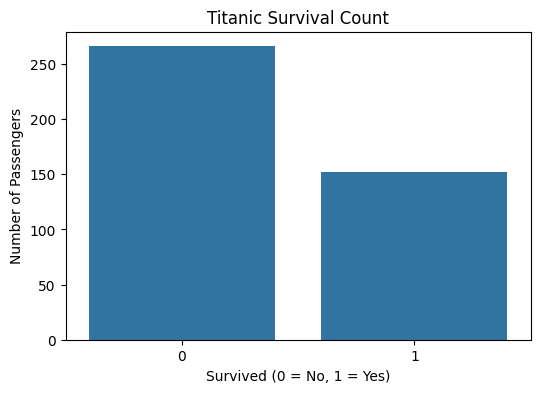

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

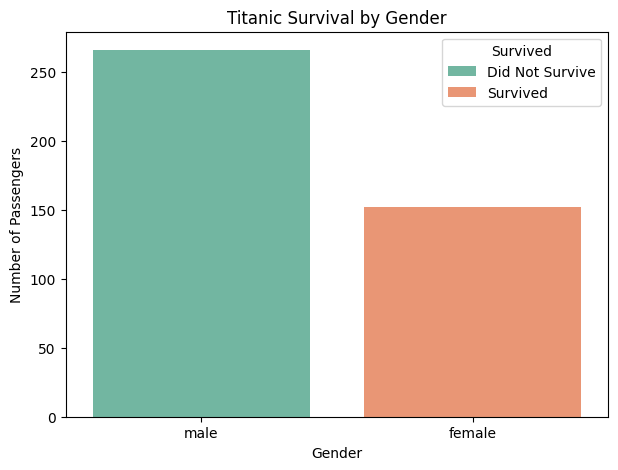

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex", hue="Survived", palette="Set2")

plt.title("Titanic Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["Did Not Survive", "Survived"])
plt.show()

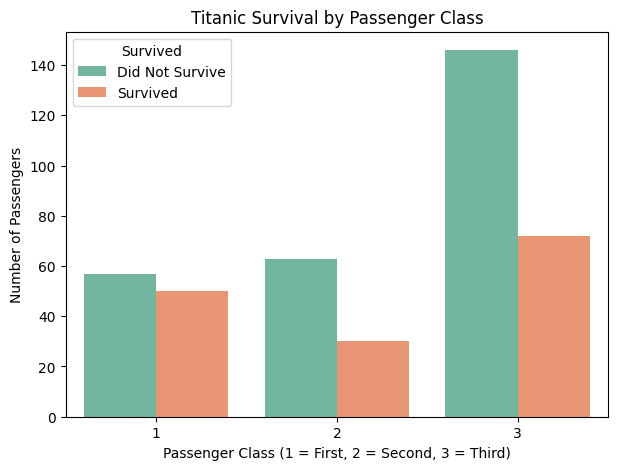

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Pclass", hue="Survived", palette="Set2")

plt.title("Titanic Survival by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["Did Not Survive", "Survived"])
plt.show()

## Conclusion and Key Findings

- The dataset contains 418 passenger records and 12 columns after removing duplicate rows.
- Missing values in Age and Fare were filled using their median values.
- Missing Cabin values were replaced with "Unknown".
- No duplicate rows were found in the dataset.
- The survival analysis shows differences in passenger survival across gender and passenger class.
- The visualizations help identify passenger survival patterns and understand the dataset before further analysis.